In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
cpu = pd.read_csv("../data/vm_cpu_readings.csv.gz")
meta = pd.read_csv("../data/vm_metadata.csv.gz")

### DATA PREPROCESSING & EXPLORATION
   

In [3]:
cpu.shape

(1340000, 5)

In [4]:
cpu.isna().sum()

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

In [5]:
cpu.duplicated().sum()  


np.int64(0)

In [6]:
print(cpu['vm_id'].nunique())                         
print(cpu['timestamp'].nunique())        

10000
134


In [7]:
meta.shape

(10000, 11)

In [8]:
meta.isna().sum()

vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64

In [9]:
meta['vm_id'].duplicated().sum() 

np.int64(0)

In [10]:
#Extract unique timestamps and sort them
times = cpu['timestamp'].drop_duplicates().sort_values() 
times

0              0
10000        300
20000        600
30000        900
40000       1200
           ...  
1290000    38700
1300000    39000
1310000    39300
1320000    39600
1330000    39900
Name: timestamp, Length: 134, dtype: int64

In [11]:
#Calculate the difference between consecutive timestamps and count the occurrences of each difference
times.diff().value_counts()   


timestamp
300.0    133
Name: count, dtype: int64

In [12]:
#Describe the CPU usage statistics
cpu[['min_cpu', 'max_cpu', 'avg_cpu']].describe().round(2)


,min_cpu,max_cpu,avg_cpu
count,1340000.00,1340000.00,1340000.00
mean,6.16,18.35,9.39
std,11.76,21.62,14.27
min,0.00,0.02,0.01
25%,1.49,4.42,2.48
50%,3.23,9.12,5.11
75%,5.33,23.62,9.62
max,99.28,99.70,99.49


In [13]:
#Checking that all rows satisfy the expected relationship between minimum, average, and maximum CPU utilization.
((cpu['min_cpu'] <= cpu['avg_cpu']) & (cpu['avg_cpu'] <= cpu['max_cpu'])).mean()

np.float64(1.0)

In [14]:
#VMs with lower than 134 readings
rows_per_vm = cpu.groupby('vm_id').size() # Count the number of rows for each VM
low_reading_vms = rows_per_vm[rows_per_vm < 134].index  # Identify VMs with fewer than 134 readings

In [15]:
print(f"Number of VMs with fewer than 134 readings: {len(low_reading_vms)}")

Number of VMs with fewer than 134 readings: 0


In [16]:
cpu['avg_cpu'].isna().sum()

np.int64(0)

In [17]:
valid = cpu.dropna(subset=['avg_cpu'])
valid = valid.drop_duplicates(['vm_id', 'timestamp'])

In [18]:
print('VMs total:', cpu['vm_id'].nunique(), '| VMs with any valid reading:', valid['vm_id'].nunique())

VMs total: 10000 | VMs with any valid reading: 10000


### TARGET CREATION & SPLITTING

In [19]:
target = valid.groupby('timestamp').agg(
    active_vm_count=('vm_id', 'nunique'),
    aggregate_cpu_utilization=('avg_cpu', 'mean'),
).sort_index()

In [20]:
print(target.shape) 
target.head()        # expect 134 rows


(134, 2)


,active_vm_count,aggregate_cpu_utilization
timestamp,,
0,10000,9.396898
300,10000,9.353775
600,10000,9.454383
900,10000,9.224419
1200,10000,9.143503


In [21]:
target['active_vm_count'].describe().round(2)

count      134.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
Name: active_vm_count, dtype: float64

In [22]:
target['active_vm_count'].value_counts()

active_vm_count
10000    134
Name: count, dtype: int64

In [23]:
TRAIN_LEN = 110   # first 110 observations = training window
HORIZON = 24      # last 24 observations = 2-hour holdout 

assert len(target) == TRAIN_LEN + HORIZON, "series should have 134 rows"

train = target.iloc[:TRAIN_LEN]      # rows 0 to 109 (110 rows)
holdout = target.iloc[TRAIN_LEN:]    # rows 110 to 133 (24 rows)

In [24]:
assert len(train) == 110 and len(holdout) == 24
print(len(train), len(holdout))   

110 24


In [25]:
# Timestamps of the 110 training observations (the index of the aggregated train table)
train_times = train.index

# VM-level readings restricted to the training window only.
# Why: the train/holdout split was made on the aggregated series, but the VM-level
# table still contains the last 24 timestamps. Filtering here prevents any VM-level
# analysis (distributions, segments, peaks) from using holdout-period information.
cpu_train = valid[valid['timestamp'].isin(train_times)].copy()   # .copy() avoids pandas warnings later

In [26]:
# Sanity checks: each should print the expected value
print(len(cpu_train))                                         # expect 1,100,000 (10,000 VMs x 110 timestamps)
print(cpu_train['timestamp'].nunique())                       # expect 110
print(cpu_train['timestamp'].max() < holdout.index.min())     # expect True: training data ends before the holdout starts

1100000
110
True


### UNDERSTANDING THE WORKLOAD

#### 1. Time Cadence & Coverage

In [27]:
#Checking for time cadence and coverage
start, end = train.index.min(), train.index.max()
print('hours covered:', (end - start) / 3600)

hours covered: 9.083333333333334


#### 2. VM & Lifetime Churn

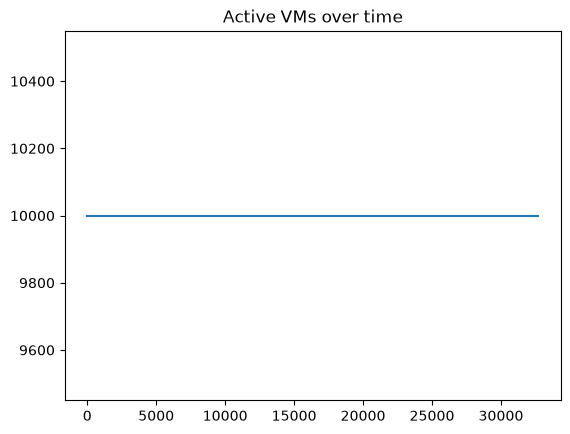

VMs that start late: 0
VMs that stop early: 0
Distribution of VM lifetimes (readings):
count    10000.0
mean       110.0
std          0.0
min        110.0
25%        110.0
50%        110.0
75%        110.0
max        110.0
Name: count, dtype: float64
Distribution of VM lifetimes (hours):
count    10000.000000
mean       636.007117
std        196.694676
min         11.250000
25%        719.833333
50%        719.833333
75%        719.833333
max        719.833333
dtype: float64


In [28]:
# Checking for VMs lifetime and churn

plt.plot(train.index, train['active_vm_count']) # 1. how many VMs report at each time
plt.title('Active VMs over time'); plt.show()

# 2. first and last time each VM is seen, and how many readings it has
life = cpu_train.groupby('vm_id')['timestamp'].agg(['min', 'max', 'count'])
print('VMs that start late:', (life['min'] > train_times.min()).sum())
print('VMs that stop early:', (life['max'] < train_times.max()).sum())
print('Distribution of VM lifetimes (readings):')
print(life['count'].describe())

# 3. lifetimes from metadata (created and deleted times)
lifetime_hours = (meta['timestamp_vm_deleted'] - meta['timestamp_vm_created']) / 3600
print('Distribution of VM lifetimes (hours):')
print(lifetime_hours.describe())

#### 3. CPU Utilization Distribution

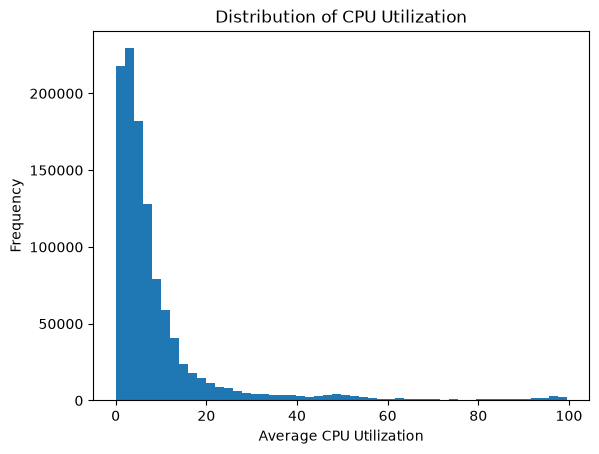

C:\Users\onwug\AppData\Local\Temp\ipykernel_13248\1172385022.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(cpu_train['avg_cpu'], vert=False)


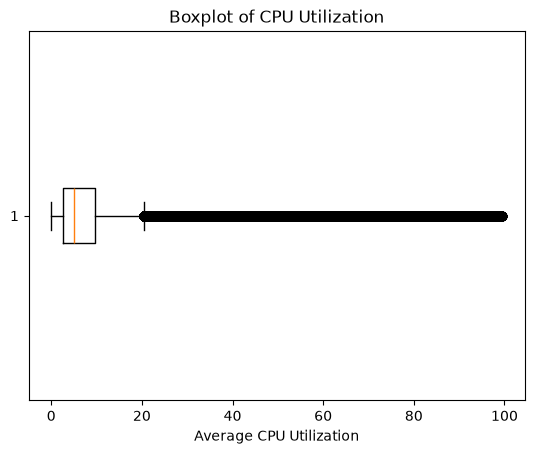

In [29]:
# Checking CPU utilization distribution and outliers
plt.hist(cpu_train['avg_cpu'], bins=50)
plt.title('Distribution of CPU Utilization')
plt.xlabel('Average CPU Utilization')
plt.ylabel('Frequency')
plt.show()

plt.boxplot(cpu_train['avg_cpu'], vert=False)
plt.title('Boxplot of CPU Utilization')
plt.xlabel('Average CPU Utilization')
plt.show()


count    1.100000e+06
mean     9.414089e+00
std      1.427521e+01
min      7.158922e-03
25%      2.486945e+00
50%      5.119809e+00
75%      9.647974e+00
max      9.948803e+01
Name: avg_cpu, dtype: float64


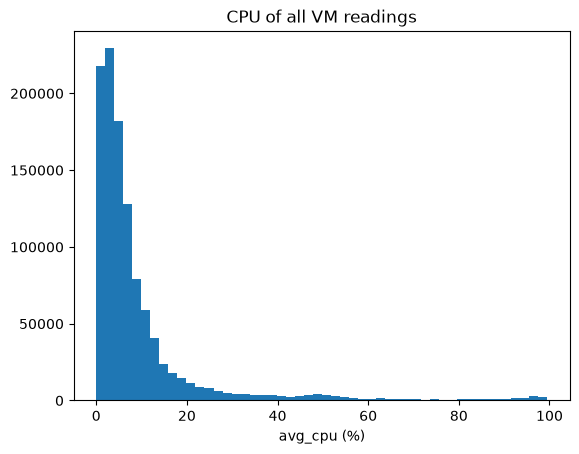

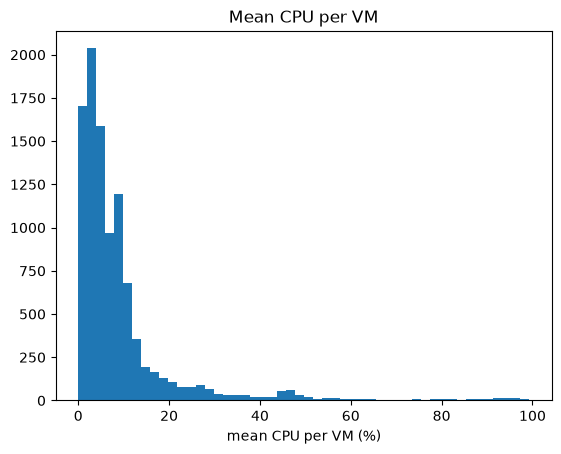

In [30]:
print(cpu_train['avg_cpu'].describe())
plt.hist(cpu_train['avg_cpu'], bins=50)
plt.xlabel('avg_cpu (%)'); plt.title('CPU of all VM readings'); plt.show()

per_vm = cpu_train.groupby('vm_id')['avg_cpu'].mean()
plt.hist(per_vm, bins=50)
plt.xlabel('mean CPU per VM (%)'); plt.title('Mean CPU per VM'); plt.show()

In [31]:
print(cpu_train['avg_cpu'].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))
print('VMs averaging under 10%:', (per_vm < 10).mean())
print('VMs averaging over 80%:', (per_vm > 80).mean())

0.50     5.119809
0.75     9.647974
0.90    19.691119
0.95    37.293248
0.99    87.406347
Name: avg_cpu, dtype: float64
VMs averaging under 10%: 0.7512
VMs averaging over 80%: 0.0099


#### 4. Temporal(Time) Patterns & Recurring Behaviour

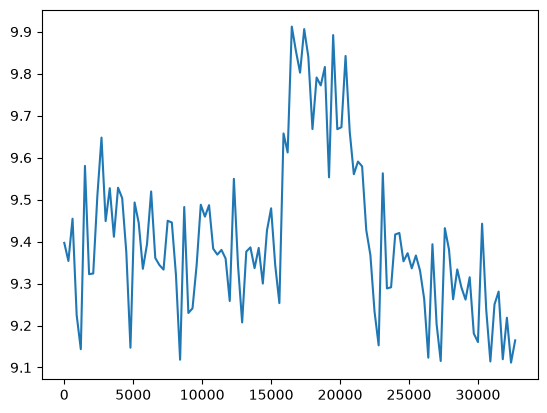

In [32]:
#Checking for temporal patterns and recurring behavior
y = train['aggregate_cpu_utilization']
plt.plot(y)
plt.show()

In [33]:
y.autocorr(1)

np.float64(0.6672358236125617)

In [34]:
y.describe()

count    110.000000
mean       9.414089
std        0.193568
min        9.111634
25%        9.288952
50%        9.378121
75%        9.507673
max        9.912175
Name: aggregate_cpu_utilization, dtype: float64

#### 5. Differences Between VM Segments

In [35]:
# stick the VM info onto every reading, matching by vm_id
seg = cpu_train.merge(meta, on='vm_id', suffixes=('', '_vm'), validate='many_to_one')

# check: we should not have gained or lost any readings
len(seg) == len(cpu_train)

True

In [36]:
for col in ['vm_category', 'virtual_core_bucket', 'memory_gb_bucket']:
    print(meta[col].value_counts(), '\n')

vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: count, dtype: int64 

virtual_core_bucket
2      7534
4      1908
8       486
24       62
>24      10
Name: count, dtype: int64 

memory_gb_bucket
2      3904
4      2475
8      2146
32     1383
64       82
>64      10
Name: count, dtype: int64 



In [37]:
for col in ['vm_category', 'virtual_core_bucket', 'memory_gb_bucket']:
    print(seg.groupby(col)['avg_cpu'].mean().round(2), '\n')

vm_category
Delay-insensitive     8.26
Interactive          11.51
Unknown              10.35
Name: avg_cpu, dtype: float64 

virtual_core_bucket
2       9.76
24     11.43
4       7.92
8       9.66
>24     6.62
Name: avg_cpu, dtype: float64 

memory_gb_bucket
2       8.80
32      7.81
4      11.46
64     11.22
8       9.14
>64     6.62
Name: avg_cpu, dtype: float64 



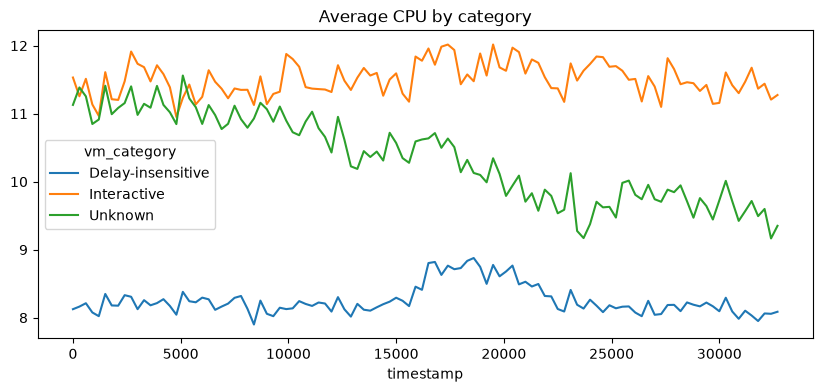

In [38]:
# one line per category, showing its average CPU over time
seg.groupby(['timestamp', 'vm_category'])['avg_cpu'].mean().unstack().plot(figsize=(10, 4))
plt.title('Average CPU by category')
plt.show()

In [39]:
busy_ids = per_vm[per_vm > 80].index                      # the VMs that average over 80%
meta[meta['vm_id'].isin(busy_ids)]['vm_category'].value_counts()

vm_category
Interactive          47
Delay-insensitive    38
Unknown              14
Name: count, dtype: int64

#### 6. Peak & Low Demand

In [40]:
y = train['aggregate_cpu_utilization']      # the average CPU over time (a short name)

peak_cut = y.quantile(0.90)                 # the line only the top 10% pass
low_cut = y.quantile(0.10)                  # the line only the bottom 10% fall under
print('peak line:', peak_cut, '| low line:', low_cut)

print('highest:', y.idxmax(), y.max())      # when it was highest, and how high
print('lowest:', y.idxmin(), y.min())       # when it was lowest, and how low

peak line: 9.668361517488389 | low line: 9.17919777090891
highest: 16500 9.912175173984915
lowest: 32400 9.111633601754887


In [41]:
peaks = y[y >= peak_cut]                    # keep only the readings at or above the peak line
print('number of peak readings:', len(peaks))
print('peaks happened between hour', (peaks.index.min() - y.index.min()) / 3600,
      'and hour', (peaks.index.max() - y.index.min()) / 3600)

number of peak readings: 11
peaks happened between hour 4.583333333333333 and hour 5.666666666666667


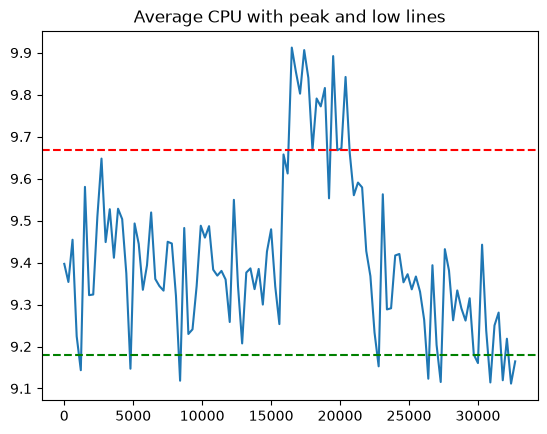

In [42]:
plt.plot(y)
plt.axhline(peak_cut, color='red', linestyle='--')     # the peak line
plt.axhline(low_cut, color='green', linestyle='--')    # the low line
plt.title('Average CPU with peak and low lines')
plt.show()

### BASELINES

In [43]:
def persistence(history, h):
    # predict that the future equals the last value
    return np.repeat(history.iloc[-1], h)

In [44]:
def moving_average(history, h, window=6):
    # predict that the future equals the mean of the last 6 values (30 minutes)
    return np.repeat(history.iloc[-window:].mean(), h)

### ROLLING ORIGIN VALIDATION - FOR TRAIN ONLY

In [45]:
def rolling_origin(series, forecast_fn, h=24, first_origin=60, step=6):
    all_actual, all_pred, all_step = [], [], []
    for origin in range(first_origin, len(series) - h + 1, step):
        history = series.iloc[:origin]               # only the past
        actual = series.iloc[origin:origin + h].values   # the next h real values
        pred = forecast_fn(history, h)
        all_actual.append(actual)
        all_pred.append(pred)
        all_step.append(np.arange(1, h + 1))
    return np.concatenate(all_actual), np.concatenate(all_pred), np.concatenate(all_step)

In [46]:
actual, pred, steps = rolling_origin(
    train['aggregate_cpu_utilization'],
    persistence
)

In [47]:
print(actual, pred, steps)

[9.66790699 9.79088517 9.77208582 9.81590448 9.55301904 9.89194553
 9.6676639  9.67245231 9.84221002 9.66217228 9.56039553 9.59058023
 9.57908264 9.42755444 9.36773248 9.23326661 9.15275393 9.56266779
 9.28833608 9.2910716  9.41689167 9.42046448 9.35293558 9.37224965
 9.6676639  9.67245231 9.84221002 9.66217228 9.56039553 9.59058023
 9.57908264 9.42755444 9.36773248 9.23326661 9.15275393 9.56266779
 9.28833608 9.2910716  9.41689167 9.42046448 9.35293558 9.37224965
 9.33618718 9.36677078 9.33068332 9.26359341 9.12323643 9.39367304
 9.57908264 9.42755444 9.36773248 9.23326661 9.15275393 9.56266779
 9.28833608 9.2910716  9.41689167 9.42046448 9.35293558 9.37224965
 9.33618718 9.36677078 9.33068332 9.26359341 9.12323643 9.39367304
 9.20380785 9.11540052 9.43190314 9.38109333 9.26248669 9.3336635
 9.28833608 9.2910716  9.41689167 9.42046448 9.35293558 9.37224965
 9.33618718 9.36677078 9.33068332 9.26359341 9.12323643 9.39367304
 9.20380785 9.11540052 9.43190314 9.38109333 9.26248669 9.33366

### METRICS

In [48]:
def mae(actual, pred):
    return np.mean(np.abs(actual - pred))



In [49]:
def rmse(actual, pred):
    return np.sqrt(np.mean((actual - pred) ** 2))

In [50]:
def relative_improvement(model_error, baseline_error):
    # 0.20 means 20 percent better than the baseline
    return 1 - model_error / baseline_error

### MACHINE LEARNING MODEL

In [51]:
#Trying Ridge Regression for Forecasting

from sklearn.linear_model import Ridge

LAGS = [1, 2, 3, 6]

In [52]:
def make_features(series):
    df = pd.DataFrame({'y': series})
    for lag in LAGS:
        df['lag_' + str(lag)] = series.shift(lag)
    df['roll_mean_6'] = series.shift(1).rolling(6).mean()
    return df.dropna()        # first rows have no lags yet

In [53]:
features = make_features(train['aggregate_cpu_utilization'])
features.head()

,y,lag_1,lag_2,lag_3,lag_6,roll_mean_6
timestamp,,,,,,
1800,9.322337,9.580335,9.143503,9.224419,9.396898,9.358885
2100,9.323858,9.322337,9.580335,9.143503,9.353775,9.346459
2400,9.509058,9.323858,9.322337,9.580335,9.454383,9.341473
2700,9.647704,9.509058,9.323858,9.322337,9.224419,9.350585
3000,9.448768,9.647704,9.509058,9.323858,9.143503,9.421133


In [54]:
def lag_model(history, h):
    data = make_features(history)
    X = data.drop(columns='y')
    y = data['y']
    model = Ridge(alpha=1.0).fit(X, y)

    values = list(history.values)          # known history
    preds = []
    for _ in range(h):                     # forecast one step, then feed it back
        row = {'lag_' + str(lag): values[-lag] for lag in LAGS}
        row['roll_mean_6'] = np.mean(values[-6:])
        x_new = pd.DataFrame([row])[X.columns]
        p = model.predict(x_new)[0]
        preds.append(p)
        values.append(p)
    return np.array(preds)

In [55]:
def clip_cpu(pred):
    return np.clip(pred, 0, 100)

def clip_count(pred):
    return np.maximum(pred, 0)

In [56]:
#Trying Simple Exponential Smoothing for Forecasting

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

def ses_forecast(history, h):
    history = history.reset_index(drop=True)  # reset index to avoid issues with statsmodels
    model = SimpleExpSmoothing(history, initialization_method="estimated")
    fitted_model = model.fit(optimized=True)
    forecast = fitted_model.forecast(steps=h)
    return forecast.values


In [57]:
y_ses = train['aggregate_cpu_utilization'].copy()
y_ses.index = pd.RangeIndex(len(y_ses))

actual, ses_predictions, steps = rolling_origin(y_ses, ses_forecast)

print('SES MAE:', mae(actual, ses_predictions))
print('SES RMSE:', rmse(actual, ses_predictions))


SES MAE: 0.23459732715016154
SES RMSE: 0.28972768567813983


In [58]:
results = []
for target_name in ['active_vm_count', 'aggregate_cpu_utilization']:
    series = train[target_name]
    for name, fn in [('persistence', persistence), ('moving_average', moving_average), ('lag_model', lag_model), ('simple_exponential_smoothing', ses_forecast)]:
        a, p, n = rolling_origin(series, fn)
        results.append({
            'target': target_name,
            'model': name,
            'MAE': mae(a, p),
            'RMSE': rmse(a, p)
        })
pd.DataFrame(results)

,target,model,MAE,RMSE
0,active_vm_count,persistence,0.000000,0.000000
1,active_vm_count,moving_average,0.000000,0.000000
2,active_vm_count,lag_model,0.000000,0.000000
3,active_vm_count,simple_exponential_smoothing,0.000000,0.000000
4,aggregate_cpu_utilization,persistence,0.280179,0.332151
5,aggregate_cpu_utilization,moving_average,0.230864,0.286452
6,aggregate_cpu_utilization,lag_model,0.171578,0.202707
7,aggregate_cpu_utilization,simple_exponential_smoothing,0.234597,0.289728


### ERROR ANALYSIS

#### 1. Performance in Peak

In [59]:
y = train['aggregate_cpu_utilization']
peak_cut = y.quantile(0.90)
a, p, step = rolling_origin(y, lag_model)
peak = a >= peak_cut
print('overall MAE:', mae(a, p))
print('peak MAE:', mae(a[peak], p[peak]))
print('non-peak MAE:', mae(a[~peak], p[~peak]))
print('bias in peaks (actual - pred):', np.mean(a[peak] - p[peak]))

overall MAE: 0.17157838354937732
peak MAE: 0.1515776500932675
non-peak MAE: 0.17300700736767086
bias in peaks (actual - pred): 0.15106251944313054


#### 2. Error By Forecast Distance

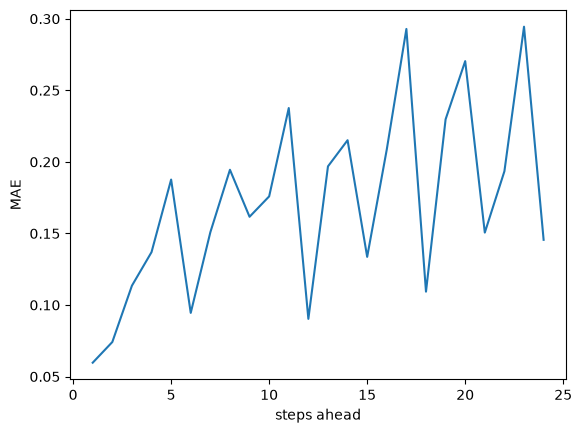

In [60]:
err_by_step = pd.Series(np.abs(a - p)).groupby(step).mean()
err_by_step.plot(); plt.xlabel('steps ahead'); plt.ylabel('MAE'); plt.show()

### WHERE & WHY IT FAILS

Worst window starts at training position: 72
MAE in worst window: 0.21070573133307766


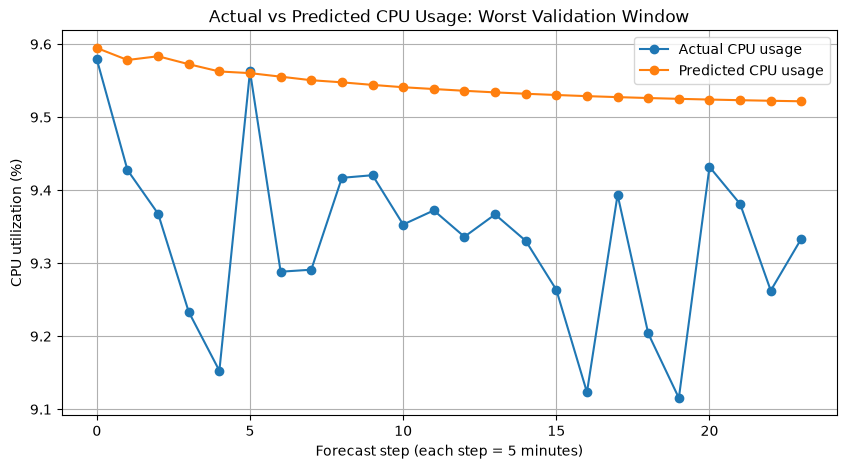


Largest sudden changes in actual CPU usage:
Step 5 to 6: 9.153% to 9.563% (change: +0.410 percentage points)
Step 20 to 21: 9.115% to 9.432% (change: +0.317 percentage points)
Step 6 to 7: 9.563% to 9.288% (change: -0.274 percentage points)


In [61]:
# Find the validation window where the model made the biggest mistakes

y = train['aggregate_cpu_utilization']

origins = range(60, len(y) - HORIZON + 1, 6)

windows = []

for origin in origins:
    history = y.iloc[:origin]
    actual = y.iloc[origin:origin + HORIZON].values
    predicted = lag_model(history, HORIZON)

    error = mae(actual, predicted)

    windows.append((origin, actual, predicted, error))

# Select the window with the biggest average mistake
worst = max(windows, key=lambda window: window[3])

origin, actual, predicted, worst_mae = worst

print('Worst window starts at training position:', origin)
print('MAE in worst window:', worst_mae)

# Plot actual CPU usage against predicted CPU usage
plt.figure(figsize=(10, 5))
plt.plot(actual, label='Actual CPU usage', marker='o')
plt.plot(predicted, label='Predicted CPU usage', marker='o')
plt.xlabel('Forecast step (each step = 5 minutes)')
plt.ylabel('CPU utilization (%)')
plt.title('Actual vs Predicted CPU Usage: Worst Validation Window')
plt.legend()
plt.grid(True)
plt.show()

# Find the biggest sudden changes in actual CPU usage
changes = np.abs(np.diff(actual))
largest_changes = np.argsort(changes)[-3:][::-1]

print('\nLargest sudden changes in actual CPU usage:')

for i in largest_changes:
    print(
        f'Step {i + 1} to {i + 2}: '
        f'{actual[i]:.3f}% to {actual[i + 1]:.3f}% '
        f'(change: {actual[i + 1] - actual[i]:+.3f} percentage points)'
    )

### FINAL PREDICTION

In [62]:
final_fn = lag_model

In [63]:
forecast = {}
for target_name in ['active_vm_count', 'aggregate_cpu_utilization']:
    forecast[target_name] = final_fn(train[target_name], HORIZON)

predictions = pd.DataFrame({
    'timestamp': holdout.index,      # the 24 required timestamps
    'active_vm_count': clip_count(forecast['active_vm_count']),
    'aggregate_cpu_utilization': clip_cpu(forecast['aggregate_cpu_utilization']),
})
predictions.to_csv('predictions.csv', index=False)    # no index column

In [64]:
#Checking file against Submission requirements

p = pd.read_csv('predictions.csv')
assert list(p.columns) == ['timestamp', 'active_vm_count', 'aggregate_cpu_utilization']
assert len(p) == 24
assert p['timestamp'].is_monotonic_increasing and not p['timestamp'].duplicated().any()
assert np.isfinite(p[['active_vm_count', 'aggregate_cpu_utilization']]).all().all()
assert (p['active_vm_count'] >= 0).all()
assert p['aggregate_cpu_utilization'].between(0, 100).all()

### ONE TIME TEST

In [65]:
for name in ['active_vm_count', 'aggregate_cpu_utilization']:
    print(name, 'MAE', mae(holdout[name].values, predictions[name].values),
          'RMSE', rmse(holdout[name].values, predictions[name].values))

active_vm_count MAE 0.0 RMSE 0.0
aggregate_cpu_utilization MAE 0.1031054048526477 RMSE 0.12471424917399633


### CAPACITY RECOMMENDATION

In [66]:
# Calculate errors from rolling-origin validation for aggregate_cpu_utilization
a, p, step = rolling_origin(
    train['aggregate_cpu_utilization'],
    final_fn
)

errors = a - p
print('share of times the actual was above the forecast:', (errors > 0).mean())

# Calculate the 90th percentile of signed validation errors
margin = np.quantile(errors, 0.90)

print('90% error margin:', margin)

# Apply the margin to the final forecast
upper = predictions['aggregate_cpu_utilization'] + margin

print('Upper capacity bound:', upper.values)

# Calculate validation coverage
upper_validation = p + margin
coverage = (a <= upper_validation).mean()

print("Validation upper-bound coverage:", coverage)
print("Validation upper-bound coverage (%):", coverage * 100)

share of times the actual was above the forecast: 0.11666666666666667
90% error margin: 0.03796046030732497
Upper capacity bound: [9.25458948 9.24792682 9.26466019 9.28520734 9.29130631 9.30381977
 9.31618821 9.32429236 9.33338865 9.34198079 9.34907562 9.35601702
 9.36244821 9.36815857 9.37351174 9.37844362 9.38292643 9.38707264
 9.39088583 9.39437782 9.3975936  9.40054955 9.40326299 9.4057583 ]
Validation upper-bound coverage: 0.9
Validation upper-bound coverage (%): 90.0


In [67]:
# Calculate errors for active VM count using rolling-origin validation
a_count, p_count, step_count = rolling_origin(
    train['active_vm_count'],
    persistence
)

# Calculate signed validation errors
count_errors = a_count - p_count

# Calculate the 90th-percentile safety margin
count_margin_90 = np.quantile(count_errors, 0.90)

print("Active VM count safety margin:", count_margin_90)

Active VM count safety margin: 0.0


In [68]:
# Calculate the CPU upper forecast line for the holdout
upper_holdout = predictions['aggregate_cpu_utilization'] + margin

# Compare actual holdout CPU values with the upper forecast line
holdout_actual = holdout['aggregate_cpu_utilization'].values

holdout_coverage = (
    holdout_actual <= upper_holdout.values
).mean()

print("Holdout upper-bound coverage:", holdout_coverage)
print("Holdout upper-bound coverage (%):", holdout_coverage * 100)
print("Holdout observations covered:", 
      (holdout_actual <= upper_holdout.values).sum(), "out of", len(holdout_actual))

Holdout upper-bound coverage: 0.75
Holdout upper-bound coverage (%): 75.0
Holdout observations covered: 18 out of 24
